# Assignment 8: Dimensionality Reduction and Unsupervised Learning

In [1]:
# show all ouputs in a cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [2]:
# import libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.datasets import make_swiss_roll
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.decomposition import IncrementalPCA
import matplotlib.pyplot as plt
from sklearn.decomposition import KernelPCA
from mpl_toolkits import mplot3d
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.manifold import LocallyLinearEmbedding
from sklearn.manifold import MDS
from sklearn.manifold import Isomap
from sklearn.manifold import TSNE
from sklearn.manifold import SpectralEmbedding
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from collections import OrderedDict
from time import time

import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from yellowbrick.cluster import SilhouetteVisualizer
from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture


## Task I

This assignment will use the breast cancer dataset that comes with the sklearn package.


### 1. Load the breast cancer dataset using the following code:


In [3]:
X, y = load_breast_cancer(return_X_y = True)

In [4]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


### 2. Use .train_test_split() function to divide the dataset into train and test sets. Asign 20% of data to the test set.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

### 3. Fit and transform the train set using principal component analysis (PCA) with n_components = 3.


In [6]:
pca_3 = PCA(n_components=3)
X_train_3D = pca_3.fit_transform(X_train)

print(X_train_3D.shape)

(455, 3)


### 4. Report the explained variance ratio of each principal component and the accumulative explained variance ratios. What is your intake regarding the correct number of dimensions (i.e., a good value for n_components)?


In [8]:
ratios = pca_3.explained_variance_ratio_
cumulative = np.cumsum(ratios)

print(f"PC1: individual: {ratios[0]:.2%}, cumulative: {cumulative[0]:.2%}")
print(f"PC2: individual: {ratios[1]:.2%}, cumulative: {cumulative[1]:.2%}")
print(f"PC3: individual: {ratios[2]:.2%}, cumulative: {cumulative[2]:.2%}")

PC1: individual: 98.18%, cumulative: 98.18%
PC2: individual: 1.61%, cumulative: 99.80%
PC3: individual: 0.18%, cumulative: 99.98%


I think a good value for n_components is n_components=1, because the first principal component explains the majority of the variation.

### 5. Choose the right number of dimensions by setting the explained variable ratio to be at least 90%. (Hint: PCA(n_components = 0.90))


In [ ]:
pca_09 = PCA(n_components=0.90)
X_train_reduced = pca_09.fit_transform(X_train)

print("Number of components kept:", pca_09.n_components_)
print("Training data shape:", X_train_reduced.shape)
print("Variance retained:", sum(pca_09.explained_variance_ratio_))

### 6. Fit a logistic regression with all features on the train set. Calculate accuracy on the test set.


In [ ]:
log_reg_full = LogisticRegression(max_iter=10000)
log_reg_full.fit(X_train, y_train)

accuracy_full = log_reg_full.score(X_test, y_test)
print(f"Test accuracy with all features: {accuracy_full:.2%}")

### 7. Fit a logistic regression using PCA-reduced feature space on the train set. Calculate accuracy on the test set.


In [ ]:
log_reg_pca = LogisticRegression(max_iter=10000)
log_reg_pca.fit(X_train_reduced, y_train)

X_test_reduced = pca_09.transform(X_test)
accuracy_pca = log_reg_pca.score(X_test_reduced, y_test)

print(f"Test accuracy with PCA-reduced features: {accuracy_pca:.2%}")

### 8. Compare the two accuracies you obtain from 6 and 7. Comment on the performance of dimensionality reduction using PCA.


The logistic regression using all 30 features achieved 95.61% test accuracy, compared with 93.86% using PCA-reduced features. Given that the reduced model only uses one principal component versus 30 features, the 1.75% decrease in accuracy is not a huge drop. I would say the dimensionality reduction using PCA is effective.

## Task II

This assignment will use the following dataset from Kaggle. The dataset can be downloaded from: https://www.kaggle.com/iamhungundji/covid19-symptoms-checker

Context (from Kaggle):

These data will help identify whether a person has a coronavirus or not based on some pre-defined common symptoms. These symptoms are based on the World Health Organization (WHO) guidelines and the Ministry of Health and Family Welfare, India.

The dataset contains seven major variables that may impact whether someone has coronavirus disease or not. The description of each variable follows:

Country: List of countries a person visited.

Age: Classification of the age group for each person, based on the WHO age group standard.

Symptoms: According to WHO, the five major symptoms of COVID-19 include fever, tiredness, difficulty in breathing, dry cough, and sore throat.

Experience any other symptoms: pains, nasal congestion, runny nose, diarrhea, and others.

Symptom severity: mild, moderate, or severe.

Contact: whether a person has contacted some other COVID-19 patient.

With all the above categorical variables, all combinations for each label in the variables are generated.


### 1. Download the “Cleaned-Data.csv” file. Read the data into Google Colab using .read_csv() function.


In [9]:
# Download latest version
path = kagglehub.dataset_download("iamhungundji/covid19-symptoms-checker")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'covid19-symptoms-checker' dataset.
Path to dataset files: /kaggle/input/covid19-symptoms-checker


In [10]:
data = pd.read_csv(path + '/Cleaned-Data.csv', decimal = ",")

### 2. Print the first and last five rows of the dataframe using .head() and .tail() functions. How many observations (i.e., sample size) do you have in total?


In [11]:
data.head()
data.tail()
print("Total observations:", len(data))

,Fever,Tiredness,Dry-Cough,Difficulty-in-Breathing,Sore-Throat,None_Sympton,Pains,Nasal-Congestion,Runny-Nose,Diarrhea,...,Gender_Male,Gender_Transgender,Severity_Mild,Severity_Moderate,Severity_None,Severity_Severe,Contact_Dont-Know,Contact_No,Contact_Yes,Country
0,1,1,1,1,1,0,1,1,1,1,...,1,0,1,0,0,0,0,0,1,China
1,1,1,1,1,1,0,1,1,1,1,...,1,0,1,0,0,0,0,1,0,China
2,1,1,1,1,1,0,1,1,1,1,...,1,0,1,0,0,0,1,0,0,China
3,1,1,1,1,1,0,1,1,1,1,...,1,0,0,1,0,0,0,0,1,China
4,1,1,1,1,1,0,1,1,1,1,...,1,0,0,1,0,0,0,1,0,China


,Fever,Tiredness,Dry-Cough,Difficulty-in-Breathing,Sore-Throat,None_Sympton,Pains,Nasal-Congestion,Runny-Nose,Diarrhea,...,Gender_Male,Gender_Transgender,Severity_Mild,Severity_Moderate,Severity_None,Severity_Severe,Contact_Dont-Know,Contact_No,Contact_Yes,Country
316795,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,1,0,1,0,Other
316796,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,1,1,0,0,Other
316797,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,1,0,0,0,1,Other
316798,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,1,0,0,1,0,Other
316799,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,1,0,1,0,0,Other


Total observations: 316800


### 3. For simplicity, remove the country column from the dataframe.


In [12]:
data = data.drop(columns=["Country"]).copy()

### 4. Use .info() to get a short description of the dataframe.


In [13]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 316800 entries, 0 to 316799
Data columns (total 26 columns):
 #   Column                   Non-Null Count   Dtype
---  ------                   --------------   -----
 0   Fever                    316800 non-null  int64
 1   Tiredness                316800 non-null  int64
 2   Dry-Cough                316800 non-null  int64
 3   Difficulty-in-Breathing  316800 non-null  int64
 4   Sore-Throat              316800 non-null  int64
 5   None_Sympton             316800 non-null  int64
 6   Pains                    316800 non-null  int64
 7   Nasal-Congestion         316800 non-null  int64
 8   Runny-Nose               316800 non-null  int64
 9   Diarrhea                 316800 non-null  int64
 10  None_Experiencing        316800 non-null  int64
 11  Age_0-9                  316800 non-null  int64
 12  Age_10-19                316800 non-null  int64
 13  Age_20-24                316800 non-null  int64
 14  Age_25-59                316800 non-

### 5. Plot a correlation matrix between features. Some sample pseudo-code could be:

```python
f, ax = plt.subplots(figsize = (30, 30))
sns.heatmap(covid_df.corr(), annot = True)
```


<Axes: >

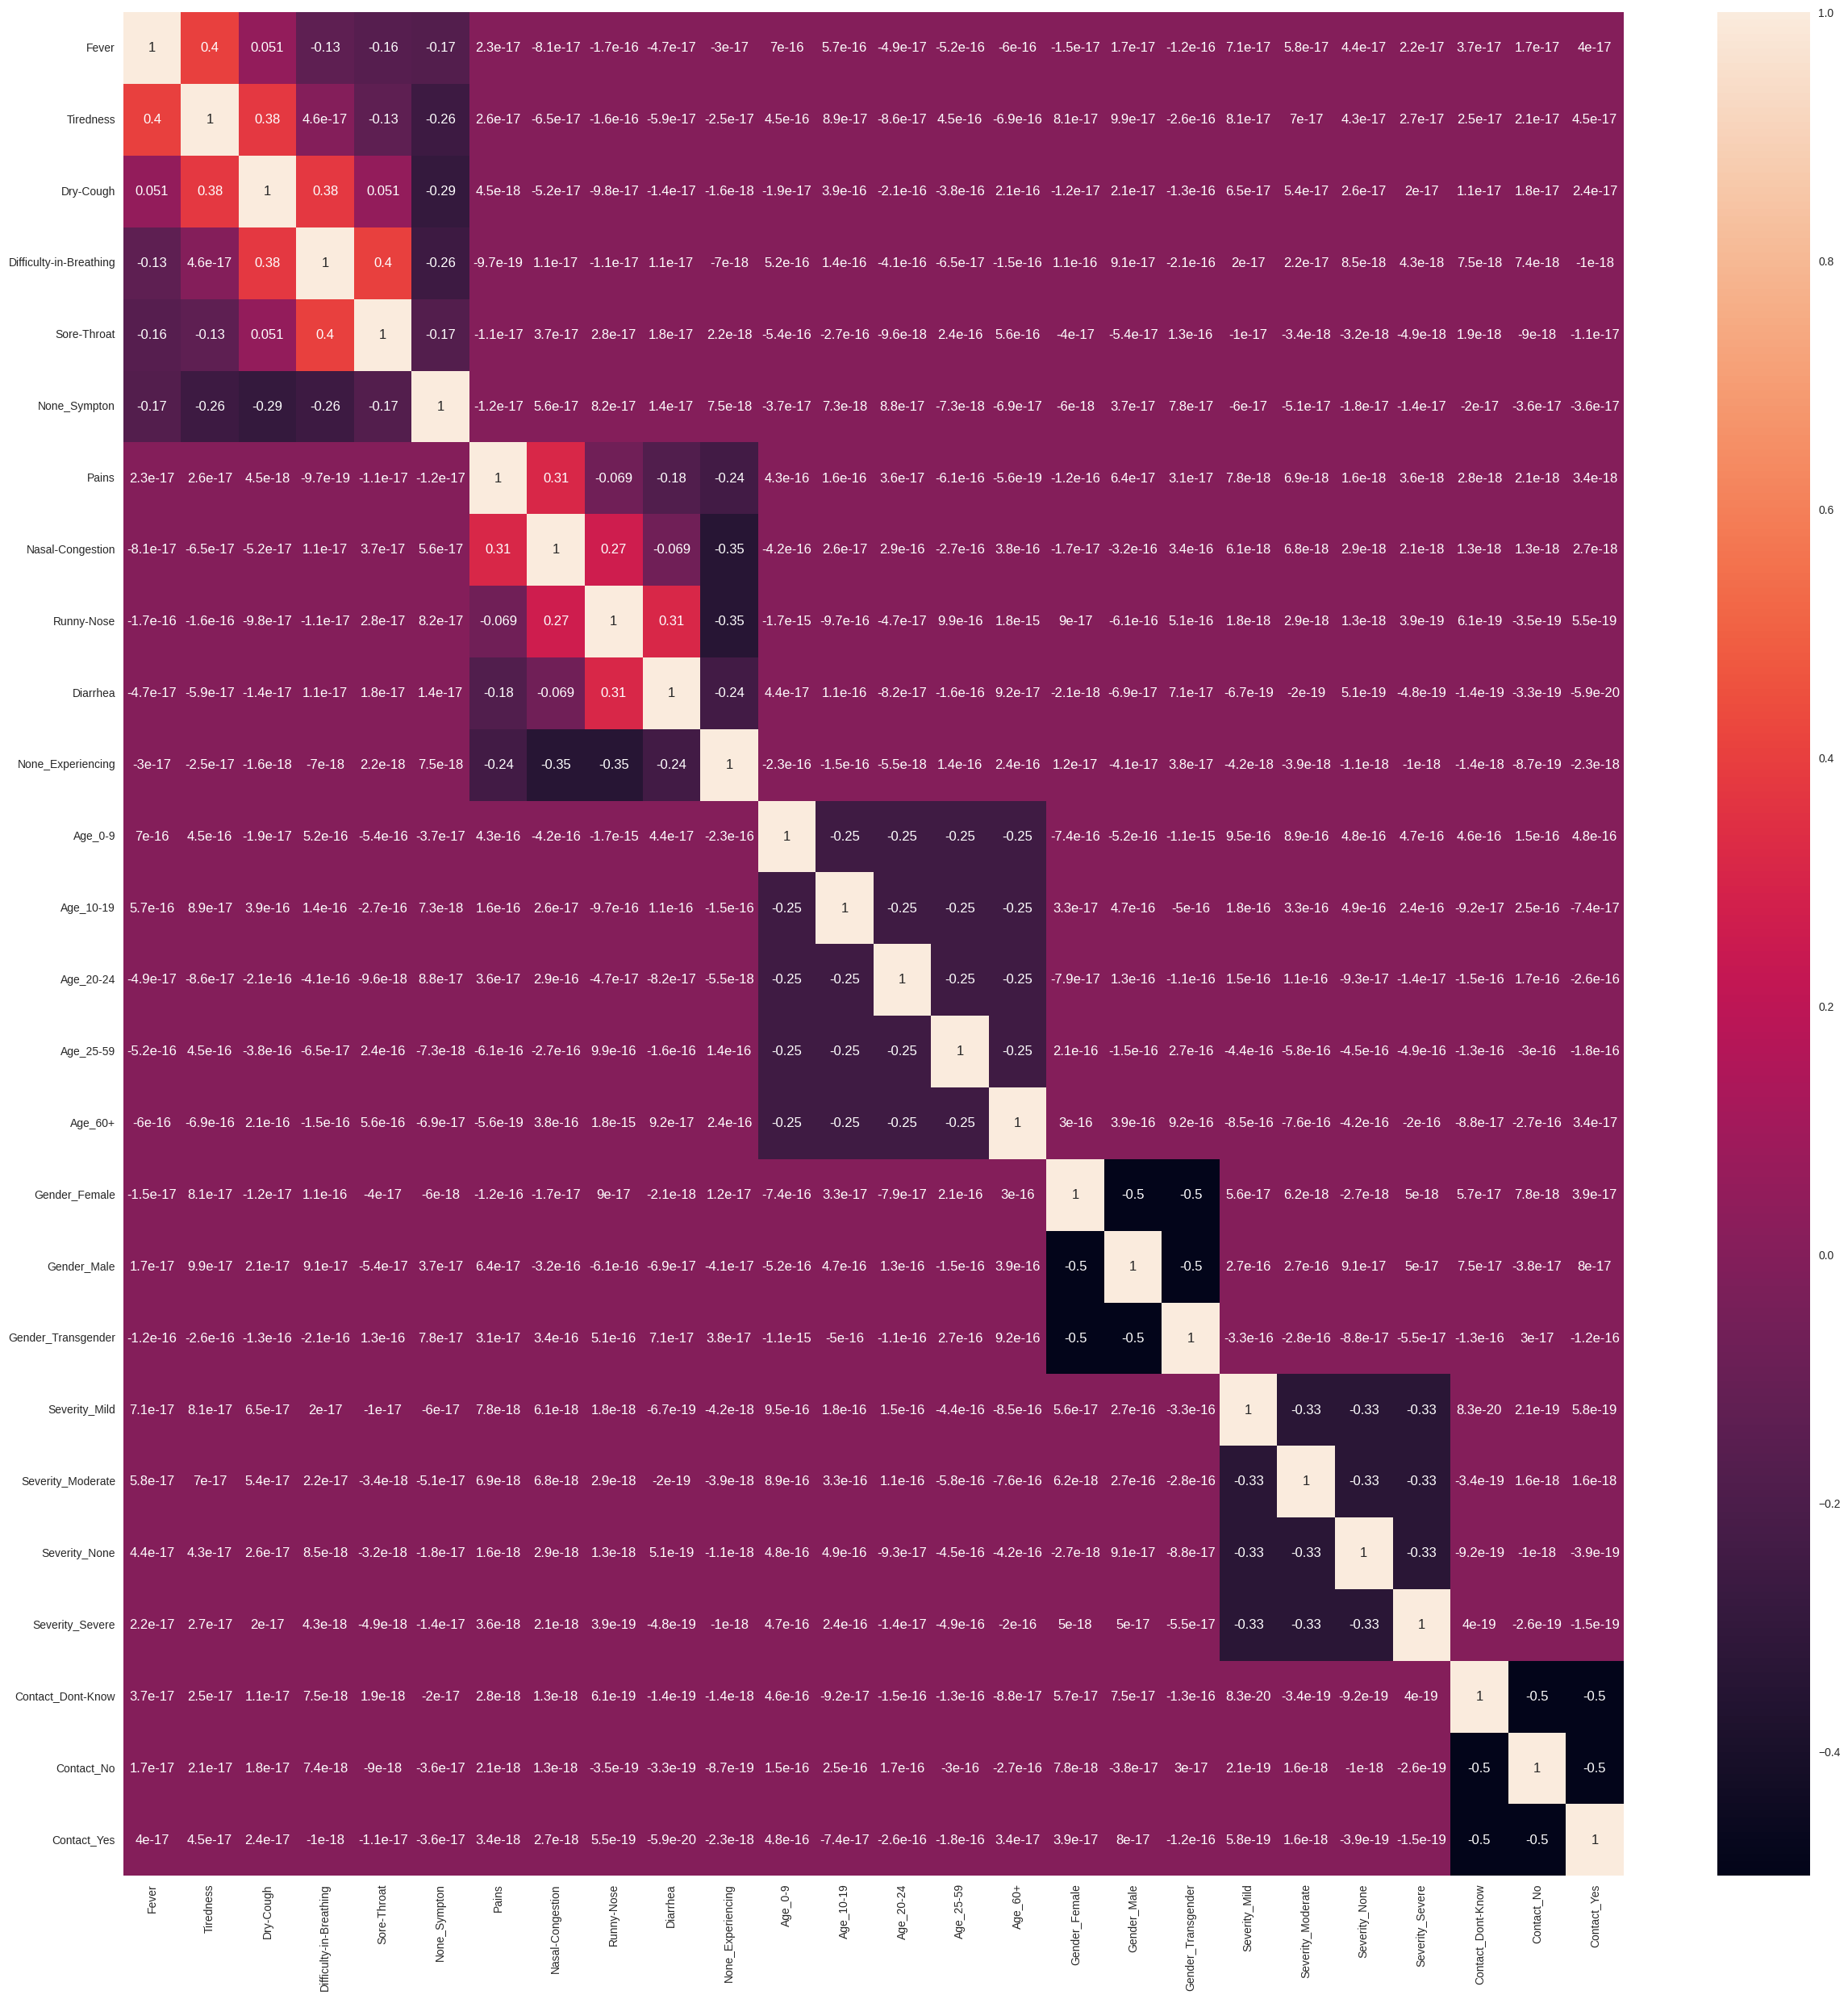

In [14]:
f, ax = plt.subplots(figsize = (30, 30))
sns.heatmap(data.corr(), annot = True)

### 6. Now, you may use the elbow method to identify the optimal number of clusters for the k-mean clustering. First, standardize the values across the columns. Some sample pseudo-code could be:

```python
Scaler = StandardScaler()
covid_df_scaled = scaler.fit_transform(covid_df)
```


In [15]:
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

### 7. Create a loop to calculate the inertias of k-mean clustering for n_clusters = 1, 2, 3, …, 20 and then plot it to help visualize where the elbow is located. A sample plot looks like this:



![Sample elbow plot](attachment:image1.png)


KMeans(n_clusters=np.int64(1), random_state=42)

KMeans(n_clusters=np.int64(2), random_state=42)

KMeans(n_clusters=np.int64(3), random_state=42)

KMeans(n_clusters=np.int64(4), random_state=42)

KMeans(n_clusters=np.int64(5), random_state=42)

KMeans(n_clusters=np.int64(6), random_state=42)

... (13 outputs left out)

KMeans(n_clusters=np.int64(20), random_state=42)

Text(0.5, 0, 'Number of clusters (k)')

Text(0, 0.5, 'Inertia')

([<matplotlib.axis.XTick at 0x7b3335db6e90>,
 [Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10'),
  Text(11, 0, '11'),
  Text(12, 0, '12'),
  Text(13, 0, '13'),
  Text(14, 0, '14'),
  Text(15, 0, '15'),
  Text(16, 0, '16'),
  Text(17, 0, '17'),
  Text(18, 0, '18'),
  Text(19, 0, '19'),
  Text(20, 0, '20')])

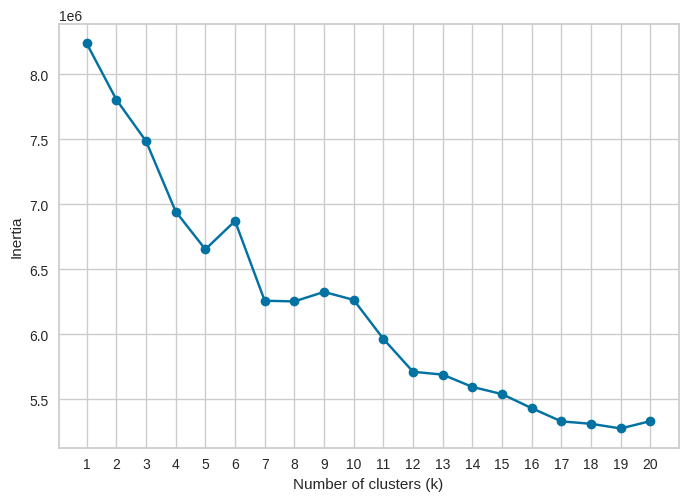

In [16]:
inertia = []

for k in np.arange(1, 21):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(data_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(np.arange(1, 21), inertia, "bo-")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(np.arange(1, 21))
plt.show()

### 8. Now, you may use the Silhouette score method to identify the optimal number of clusters for the k-mean clustering based on the standardized data. Create a loop to calculate the Silhouette score of k-mean clustering for n_clusters = 2, 3, …, 20. Then plot the Silhouette scores against the number of clusters. Based on the plot, what is the optimal number of clusters?


In [ ]:
from sklearn.metrics import silhouette_score

silhouette = []

for k in np.arange(2, 21):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(data_scaled)

    score = silhouette_score(
        data_scaled,
        kmeans.labels_,
        sample_size=2000,
        random_state=42
    )
    silhouette.append(score)

plt.plot(np.arange(2, 21), silhouette, "bo-")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.xticks(np.arange(2, 21))
plt.show()

print("Highest-scoring k:", np.argmax(silhouette) + 2)

### 9. Use .SilhouetteVisualizer() to visualize the performance of the k-mean clustering for n_clusters equaling the optimal number of clusters.


In [ ]:
optimal_k = 5

# Use a sample so the visualization is practical to compute
rng = np.random.default_rng(42)
indices = rng.choice(len(data_scaled), size=2000, replace=False)
data_sample = data_scaled[indices]

kmeans_sample = KMeans(n_clusters=optimal_k, random_state=42)
visualizer = SilhouetteVisualizer(kmeans_sample, colors="yellowbrick")
visualizer.fit(data_sample)
visualizer.show()

### 10. Compare the optimal number of clusters identified by the elbow method and the Silhouette score method. Are they the same or similar, or are they very different? Which one do you prefer?


The elbow method plot suggests k=12 and the Silhouette score method suggests k=5, which are quite different. I prefer the Silhouette score method because it returns a smaller amount of clusters and the diagnostics plot suggests a balanced performance across clusters.

### 11. Use the optimal number of clusters identified by the Silhouette score method to fit the k-mean clustering model on the standardized data. Then return an array with cluster labels. Some sample pseudo-code could be:

```python
covid_means = KMeans(n_clusters = …)
covid_means.fit(covid_df_scaled)
labels = covid_means.labels_
```


In [ ]:
covid_means = KMeans(n_clusters=optimal_k, random_state=42)
covid_means.fit(data_scaled)

labels = covid_means.labels_

print("First 10 labels:", labels[:10])
print("Number of labels:", len(labels))

### 12. Create a dataframe with cluster centers. Some sample pseudo-code could be:

```python
covid_df_m = pd.DataFrame(covid_means.cluster_centers_, columns = covid_df.columns)
```


In [ ]:
covid_df_m = pd.DataFrame(covid_means.cluster_centers_, columns=data.columns)

covid_df_m.index.name = "Cluster"
display(covid_df_m)

### 13. Examine the above dataframe. Could you tell which cluster(s) denote(s) people with Covid-19, and which cluster(s) denote(s) people without Covid-19? Briefly discuss the reasons that lead you to the conclusion.


The five clusters primarily separate the generated profiles by age group: clusters 0–4 correspond to ages 25–59, 60+, 20–24, 0–9, and 10–19, respectively. The symptom averages shown are nearly identical across clusters. Therefore, these clusters do not provide a basis for identifying which people have COVID-19. The dataset contains generated combinations rather than confirmed patient diagnoses.

## Task III

This assignment will use the following dataset from Kaggle. The dataset can be downloaded from: https://www.kaggle.com/rohan0301/unsupervised-learning-on-country-data

This project aims to categorize the countries using socio-economic and health factors that determine a country's overall development.

Variable definitions:

country: Name of the country

child_mort: Death of children under five years of age per 1000 live births

exports: Exports of goods and services per capita given as % of the GDP per capita

health: Total health spending per capita given as % of GDP per capita

imports: Imports of goods and services per capita given as % of the GDP per capita

income: Net income per person

inflation: The measurement of the annual growth rate of the total GDP

life_expec: The average number of years a newborn child would live if the current mortality patterns remain the same

total_fer: The number of children that would be born if the current age-fertility rates remain the same

gdpp: GDP per capita calculated as the total GDP divided by the total population


### 1. Download the "Country-data.csv" file. Read the data into Google Colab using .read_csv() function.


In [17]:
path = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")
country_dat = pd.read_csv(path + '/Country-data.csv', decimal = ",")

Using Colab cache for faster access to the 'unsupervised-learning-on-country-data' dataset.


### 2. Set country as the index for the dataframe.


In [18]:
country_dat = country_dat.set_index("country")

### 3. Print the first and last five rows of the dataframe using .head() and .tail() functions. How many observations (i.e., sample size) do you have in total?


In [19]:
country_dat.head()
country_dat.tail()
print("Total observations:", len(country_dat))

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
country,,,,,,,,,
Afghanistan,90.2,10,7.58,44.9,1610,9.44,56.2,5.82,553
Albania,16.6,28,6.55,48.6,9930,4.49,76.3,1.65,4090
Algeria,27.3,38.4,4.17,31.4,12900,16.1,76.5,2.89,4460
Angola,119,62.3,2.85,42.9,5900,22.4,60.1,6.16,3530
Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
country,,,,,,,,,
Vanuatu,29.2,46.6,5.25,52.7,2950,2.62,63,3.5,2970
Venezuela,17.1,28.5,4.91,17.6,16500,45.9,75.4,2.47,13500
Vietnam,23.3,72,6.84,80.2,4490,12.1,73.1,1.95,1310
Yemen,56.3,30,5.18,34.4,4480,23.6,67.5,4.67,1310
Zambia,83.1,37,5.89,30.9,3280,14,52,5.4,1460


Total observations: 167


### 4. Use .info() to get a short description of the dataframe.


In [20]:
country_dat.info()

<class 'pandas.core.frame.DataFrame'>
Index: 167 entries, Afghanistan to Zambia
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   child_mort  167 non-null    object
 1   exports     167 non-null    object
 2   health      167 non-null    object
 3   imports     167 non-null    object
 4   income      167 non-null    int64 
 5   inflation   167 non-null    object
 6   life_expec  167 non-null    object
 7   total_fer   167 non-null    object
 8   gdpp        167 non-null    int64 
dtypes: int64(2), object(7)
memory usage: 13.0+ KB


### 5. Fit a gussian mixture model (GMM) with three components.


In [21]:
X = country_dat.to_numpy()

gm = GaussianMixture(n_components=3, random_state=42)
gm.fit(X)

GaussianMixture(n_components=3, random_state=42)

### 6. Report the relative weights of the three components.


In [22]:
print("Component weights:", gm.weights_)
print("Sum:", gm.weights_.sum())

Component weights: [0.51083328 0.18502078 0.30414594]
Sum: 1.0


### 7. Report the means of the three components.


In [23]:
component_means = pd.DataFrame(
    gm.means_,
    columns=country_dat.columns,
    index=["Component 0", "Component 1", "Component 2"]
)

display(component_means)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
Component 0,63.619782,31.777279,6.264395,45.308938,4925.378304,9.856113,64.452651,3.897933,2253.857155
Component 1,4.834032,55.257204,9.001129,47.503604,48185.161151,2.728896,80.452576,1.731560,45918.073679
Component 2,16.033624,48.175403,6.412156,49.172932,18785.012605,7.371788,74.785583,2.092402,10905.990021


### 8. Report the variance-covariance matrix of the three components.


In [24]:
print("Component 1")
display(pd.DataFrame(gm.covariances_[0],
                     index=country_dat.columns,
                     columns=country_dat.columns))

print("\nComponent 2")
display(pd.DataFrame(gm.covariances_[1],
                     index=country_dat.columns,
                     columns=country_dat.columns))

print("\nComponent 3")
display(pd.DataFrame(gm.covariances_[2],
                     index=country_dat.columns,
                     columns=country_dat.columns))

Component 1


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
child_mort,1681.496764,-182.228696,-2.744766,-130.762684,-9.288972e+04,86.420475,-267.152859,45.754490,-4.234969e+04
exports,-182.228696,279.507211,-8.060921,117.665239,3.105432e+04,1.697907,22.396339,-6.260390,1.405030e+04
health,-2.744766,-8.060921,6.905989,20.604741,-6.766705e+02,-2.910181,-2.295167,-0.014317,5.576999e+01
imports,-130.762684,117.665239,20.604741,352.348883,-5.070103e+03,-59.011254,-2.251178,-5.073511,-4.221793e+02
income,-92889.720687,31054.320818,-676.670454,-5070.102839,1.505043e+07,1280.340595,15816.963920,-3717.467474,6.751305e+06
inflation,86.420475,1.697907,-2.910181,-59.011254,1.280341e+03,153.600916,-4.759261,3.676094,-5.911179e+01
life_expec,-267.152859,22.396339,-2.295167,-2.251178,1.581696e+04,-4.759261,62.535332,-7.046260,6.488818e+03
total_fer,45.754490,-6.260390,-0.014317,-5.073511,-3.717467e+03,3.676094,-7.046260,2.293308,-1.516512e+03
gdpp,-42349.688012,14050.295565,55.769990,-422.179262,6.751305e+06,-59.111795,6488.818132,-1516.512077,3.497241e+06



Component 2


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
child_mort,4.646999,-7.075768,-3.126230,-22.168914,2.329314e+04,6.863159,-2.263684,0.269525,-4.261364e+03
exports,-7.075768,1658.707651,-58.879427,1312.172867,4.521210e+05,16.079441,2.317921,-1.819296,2.904712e+05
health,-3.126230,-58.879427,10.855349,-28.457070,-4.100556e+04,-8.382174,1.481422,-0.042876,1.218109e+03
imports,-22.168914,1312.172867,-28.457070,1143.674400,2.014228e+05,-18.387930,7.934109,-2.921216,1.823714e+05
income,23293.136537,452121.021820,-41005.560136,201422.766049,4.431100e+08,47003.654833,-7534.970693,1595.887851,2.312026e+08
inflation,6.863159,16.079441,-8.382174,-18.387930,4.700365e+04,17.273876,-4.086940,0.478182,2.929706e+03
life_expec,-2.263684,2.317921,1.481422,7.934109,-7.534971e+03,-4.086940,2.111630,-0.120092,6.451992e+03
total_fer,0.269525,-1.819296,-0.042876,-2.921216,1.595888e+03,0.478182,-0.120092,0.090343,1.164914e+03
gdpp,-4261.364394,290471.175858,1218.108750,182371.425373,2.312026e+08,2929.705960,6451.991555,1164.914043,3.223432e+08



Component 3


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
child_mort,234.619546,3.320726,-7.091089,-42.246028,-2.296995e+03,52.107024,-34.031201,8.072416,-1.265263e+04
exports,3.320726,659.337356,-3.395772,557.246311,9.506827e+04,-35.344496,2.262531,-0.375094,5.031219e+04
health,-7.091089,-3.395772,2.877546,2.148342,-3.412892e+03,-5.774208,2.672835,-0.471172,1.532151e+03
imports,-42.246028,557.246311,2.148342,618.347114,2.491309e+04,-87.950079,7.668679,-3.822352,2.121971e+04
income,-2296.995228,95068.269973,-3412.891831,24913.094275,8.017352e+07,9506.814706,1834.872522,1276.529183,4.351908e+07
inflation,52.107024,-35.344496,-5.774208,-87.950079,9.506815e+03,73.770984,-9.747685,2.710156,-4.256241e+03
life_expec,-34.031201,2.262531,2.672835,7.668679,1.834873e+03,-9.747685,12.125070,-0.890445,5.374685e+03
total_fer,8.072416,-0.375094,-0.471172,-3.822352,1.276529e+03,2.710156,-0.890445,0.435341,2.988515e+02
gdpp,-12652.630989,50312.193114,1532.150952,21219.706846,4.351908e+07,-4256.240944,5374.684832,298.851459,3.844038e+07


### 9. Check the convergence status of the GMM.


In [25]:
gm.converged_

True

### 10. Report the number of iterations.


In [26]:
gm.n_iter_

16

### 11. Create a dataframe with two columns: the predicted labels and their corresponding country names. Print the country names under lable 1, label 2, and label 3 separately. Does the classification make sense to you based on your prior knowledge of those countries?


In [27]:
country_groups = pd.DataFrame({"country": country_dat.index,
                               "label": gm.predict(X)})

print("Label 1:", country_groups.loc[country_groups["label"] == 0, "country"].tolist())
print("Label 2:", country_groups.loc[country_groups["label"] == 1, "country"].tolist())
print("Label 3:", country_groups.loc[country_groups["label"] == 2, "country"].tolist())

Label 1: ['Afghanistan', 'Angola', 'Armenia', 'Azerbaijan', 'Bangladesh', 'Belize', 'Benin', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chad', 'China', 'Comoros', 'Congo, Dem. Rep.', 'Congo, Rep.', "Cote d'Ivoire", 'El Salvador', 'Eritrea', 'Fiji', 'Gabon', 'Gambia', 'Georgia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'India', 'Indonesia', 'Iraq', 'Jordan', 'Kenya', 'Kiribati', 'Kyrgyz Republic', 'Lao', 'Lesotho', 'Liberia', 'Madagascar', 'Malawi', 'Mali', 'Mauritania', 'Micronesia, Fed. Sts.', 'Moldova', 'Mongolia', 'Montenegro', 'Morocco', 'Mozambique', 'Myanmar', 'Namibia', 'Nepal', 'Niger', 'Nigeria', 'Pakistan', 'Paraguay', 'Peru', 'Philippines', 'Rwanda', 'Samoa', 'Senegal', 'Serbia', 'Sierra Leone', 'Solomon Islands', 'South Africa', 'Sri Lanka', 'Sudan', 'Tajikistan', 'Tanzania', 'Thailand', 'Timor-Leste', 'Togo', 'Tonga', 'Turkmenistan', 'Uga

The label 2 pretty accurately captured the developed countries, while the label 1 and 3 are mostly developing countries. I can't identify the major differences between the countries in label 1 and 3.

### 12. Now, use AIC to select the optimal number of components in a GMM. You may use the following pseudo-code to loop through different number of components, calculate AIC from the fitted GMM, and make a plot.

```python
aics = []
for i in np.arange(2, 11):
gm = GaussianMixture(n_components = i, n_init = 10, random_state = 42)
gm.fit(X)
aics.append(gm.aic(X))
plt.plot(np.arange(2, 11), aics)
```

Based on the plot, what is the optimal number of components?


GaussianMixture(n_components=np.int64(2), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(3), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(4), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(5), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(6), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(7), n_init=10, random_state=42)

... (8 outputs left out)

GaussianMixture(n_components=np.int64(16), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(17), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(18), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(19), n_init=10, random_state=42)

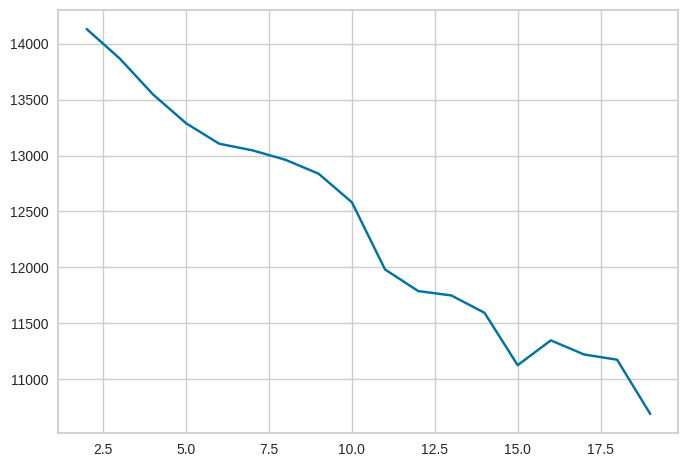

In [28]:
aics = []

for i in np.arange(2, 20):
  gm = GaussianMixture(n_components = i, n_init = 10, random_state = 42)
  gm.fit(X)
  aics.append(gm.aic(X))

plt.plot(np.arange(2, 20), aics)

Based on the AIC plot, I would choose number of components to be 11. Even though the AIC score keeps dropping after 11, the rate became smaller and it doesn't make sense to have more than 11 components with a 160+ sample size.

### 13. Now, repeat the above process for BIC. Based on the plot, what is the optimal number of components? Does the optimal number of components suggested by AIC agree with that suggested by BIC?


GaussianMixture(n_components=np.int64(2), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(3), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(4), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(5), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(6), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(7), n_init=10, random_state=42)

... (8 outputs left out)

GaussianMixture(n_components=np.int64(16), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(17), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(18), n_init=10, random_state=42)

GaussianMixture(n_components=np.int64(19), n_init=10, random_state=42)

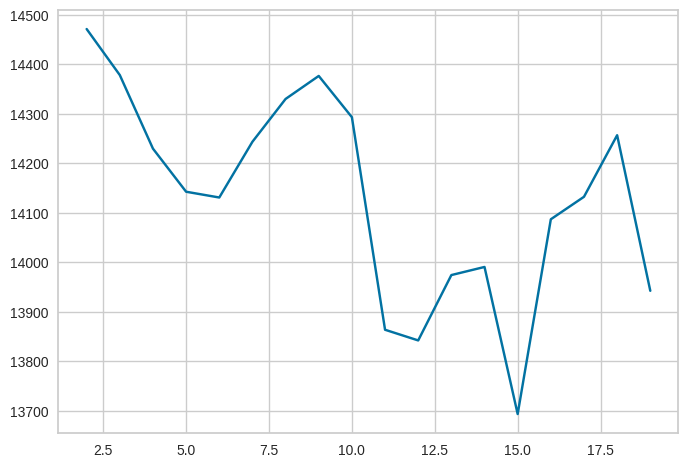

In [29]:
bics = []

for i in np.arange(2, 20):
  gm = GaussianMixture(n_components = i, n_init = 10, random_state = 42)
  gm.fit(X)
  bics.append(gm.bic(X))

plt.plot(np.arange(2, 20), bics)

Based on the BIC plot, the optimal number of components is 15.

### 14. Now, use Bayesian GMM to select the optimal number of components. You may use the following pseudo-code.

```python
bgm = BayesianGaussianMixture(n_components = 10, n_init = 10)
bgm.fit(X)
np.round(bgm.weights_, 2)
```

What is the optimal number of components suggested by the Bayesian GMM?


In [ ]:

bgm = BayesianGaussianMixture(n_components = 10, n_init = 10)
bgm.fit(X)
np.round(bgm.weights_, 2)

 There is no apparant answer to this question as all the components have non-zero weights. But the first 3 components take up 86% of the weight, so I would say the optimal number of components suggested by the Bayesian GMM is 3.

### 15. Fit the Bayesian GMM using the optimal number of components. Create a dataframe with two columns: the predicted labels by the Bayesian GMM and their corresponding country names. Print the country names in each group. Does the classification make sense to you based on your prior knowledge of those countries?


In [31]:
bgm_3 = BayesianGaussianMixture(n_components=3, n_init=10, random_state=42).fit(X)

bayesian_groups = pd.DataFrame({"country": country_dat.index,
                                "label": bgm_3.predict(X)})

print("Label 1:", bayesian_groups.loc[bayesian_groups["label"] == 0, "country"].tolist())
print("Label 2:", bayesian_groups.loc[bayesian_groups["label"] == 1, "country"].tolist())
print("Label 3:", bayesian_groups.loc[bayesian_groups["label"] == 2, "country"].tolist())

Label 1: ['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belize', 'Benin', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chad', 'China', 'Comoros', 'Congo, Dem. Rep.', 'Congo, Rep.', 'Costa Rica', "Cote d'Ivoire", 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Eritrea', 'Fiji', 'Gabon', 'Gambia', 'Georgia', 'Ghana', 'Grenada', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'India', 'Indonesia', 'Iran', 'Iraq', 'Jamaica', 'Jordan', 'Kazakhstan', 'Kenya', 'Kiribati', 'Kyrgyz Republic', 'Lao', 'Lebanon', 'Lesotho', 'Liberia', 'Macedonia, FYR', 'Madagascar', 'Malawi', 'Maldives', 'Mali', 'Mauritania', 'Micronesia, Fed. Sts.', 'Moldova', 'Mongolia', 'Montenegro', 'Morocco', 'Mozambique', 'Myanmar', 'Namibia', 'Nepal', 'Niger', 'Nigeria', 'Pakistan', 'Panama', 'Paraguay', 'Peru', 'Philippines', 'Russi

The 3 groups by the Bayesian GMM doesn't make much sense to me.